# 02 — Prophet Forecasting

**Project:** Time Series Forecaster — daily sales

**Pipeline (recap from notebook 01):** order lines → status filter → daily aggregation
→ observed-days-only series (missing dates are **not** zero-filled) → temporal split → Prophet.

**What this notebook covers:**
1. Load raw data and rebuild the canonical daily series
2. Prophet format (`ds` / `y`) and temporal train/test split
3. Fit a default Prophet model and forecast the **exact test dates**
4. Evaluate with MAE / RMSE / MAPE and compare against the naive baseline
5. Inspect components (trend, weekly, yearly seasonality)
6. Experiment: enabling yearly seasonality
7. Time-series cross-validation with Prophet's built-in diagnostics


## 1. Load the raw data

In [45]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_squared_error

project_root = Path("..").resolve()
csv_path = project_root / "data" / "raw" / "sales_data.csv"

print(f"Project root: {project_root}")
print(f"CSV path: {csv_path}")
df = pd.read_csv(csv_path, encoding="latin1")
df.head()

Project root: D:\projects\time-series-forecaster
CSV path: D:\projects\time-series-forecaster\data\raw\sales_data.csv


,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium


## 2. Status filter

Keep only statuses that represent completed revenue. Note the side effect:
some calendar dates had *only* cancelled/disputed orders, so they disappear
from the series entirely — that's why we now have **240 observed days**
instead of the 252.

In [46]:
# Keep only statuses that represent completed revenue
valid_statuses = ["Shipped", "Resolved"]
df = df[df["STATUS"].isin(valid_statuses)].copy()

print(f"Rows after status filter: {len(df)} (/2823)")

Rows after status filter: 2664 (/2823)


## 3. Clean, parse dates, aggregate to daily

One row per observed sales day — the single canonical series.

In [47]:
df = df[["ORDERNUMBER", "QUANTITYORDERED", "PRICEEACH", "ORDERDATE", "SALES"]].copy()
df["ORDERDATE"] = pd.to_datetime(df["ORDERDATE"], format="%m/%d/%Y %H:%M")

df = df.rename(columns={
    "ORDERNUMBER": "order_number",
    "QUANTITYORDERED": "quantity_ordered",
    "PRICEEACH": "price_each",
    "ORDERDATE": "date",
    "SALES": "sales",
})

df = df.sort_values("date").reset_index(drop=True)

daily_sales = (
    df.groupby("date", as_index=False)["sales"]
      .sum()
      .rename(columns={"sales": "daily_sales"})
)

print(f"Rows after aggregation: {len(daily_sales)}")
print(f"First date: {daily_sales['date'].min()}")
print(f"Last date:  {daily_sales['date'].max()}")
daily_sales.head()

Rows after aggregation: 240
First date: 2003-01-06 00:00:00
Last date:  2005-05-17 00:00:00


,date,daily_sales
0,2003-01-06,12133.25
1,2003-01-09,11432.34
2,2003-01-10,6864.05
3,2003-01-29,54702.00
4,2003-01-31,44621.96


In [48]:
daily_sales.info()
daily_sales.isna().sum()

<class 'pandas.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   date         240 non-null    datetime64[us]
 1   daily_sales  240 non-null    float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 3.9 KB


date           0
daily_sales    0
dtype: int64

**Observation:** 240 rows, no nulls, correct dtypes. The series is
*irregular* — one row per day that had recorded sales, nothing in between.
Prophet handles gaps in `ds` natively (it does not assume missing dates are
zeros), which is exactly why we avoided zero-filling.

## 4. Prophet format and train/test split

Prophet expects two columns: **`ds` (datetime) and `y` (value).**

Split is **temporal, never shuffled**: 80% of observations for training,
the final 20% (most recent observed days) for testing.

In [49]:
prophet_df = daily_sales[["date", "daily_sales"]].rename(
    columns={"date": "ds", "daily_sales": "y"}
)

split_idx = int(len(prophet_df) * 0.8)

train = prophet_df.iloc[:split_idx].copy()
test  = prophet_df.iloc[split_idx:].copy()

print(f"Training samples: {len(train)}")
print(f"Testing samples:  {len(test)}")
print("Train:", train["ds"].min(), "→", train["ds"].max())
print("Test :", test["ds"].min(), "→", test["ds"].max())

Training samples: 192
Testing samples:  48
Train: 2003-01-06 00:00:00 → 2004-12-03 00:00:00
Test : 2004-12-04 00:00:00 → 2005-05-17 00:00:00


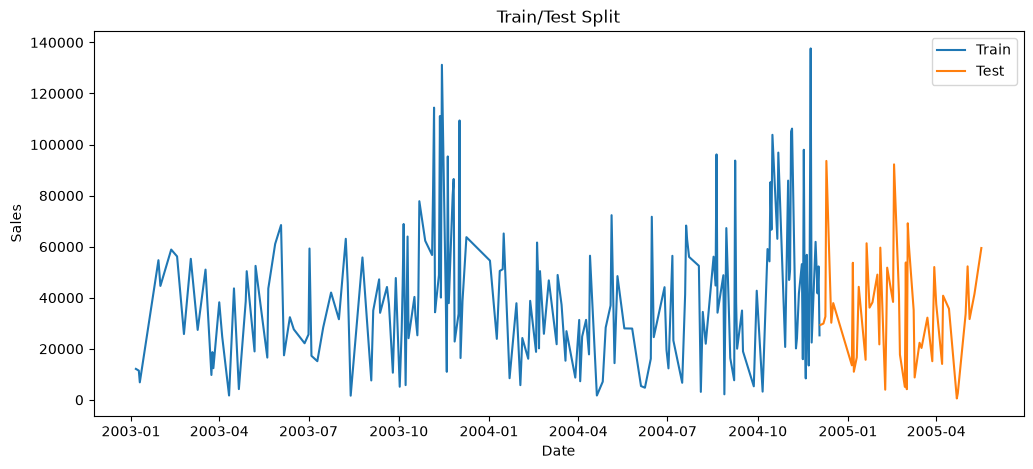

In [50]:
plt.figure(figsize=(12, 5))
plt.plot(train["ds"], train["y"], label="Train")
plt.plot(test["ds"], test["y"], label="Test")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.title("Train/Test Split")
plt.legend()
plt.show()

**Observation:** the test window (Dec 2004 → May 2005) sits on a
relatively flat part of the series, after the strong 2004 peaks. Remember it
spans ~165 calendar days even though it contains only 48 observations —
this matters for forecasting, next section.

## 5. Default Prophet model

Start from defaults and understand the output before tuning anything.

In [51]:
model = Prophet()
model.fit(train)

12:27:36 - cmdstanpy - INFO - Chain [1] start processing
12:27:37 - cmdstanpy - INFO - Chain [1] done processing


### Forecasting the test window 

In [68]:
# Predict on the exact test dates
forecast_test = model.predict(test[["ds"]])

results = test.merge(
    forecast_test[["ds", "yhat", "yhat_lower", "yhat_upper"]],
    on="ds"
)

# every test day must have a prediction
assert len(results) == len(test), f"Only {len(results)}/{len(test)} test days matched!"
results.head()

,ds,y,yhat,yhat_lower,yhat_upper
0,2004-12-04,29343.35,38050.142613,5951.665710,73716.940839
1,2004-12-07,29884.13,52092.851240,14825.350927,83975.002225
2,2004-12-09,32623.93,49283.822268,15822.839375,83269.669100
3,2004-12-10,93587.56,46876.228042,13331.362502,80517.241640
4,2004-12-15,30214.42,51142.270288,19046.824085,88354.868194


## 6. Evaluation

- **MAE** — average absolute error in dollars. Robust, easy to explain.
- **RMSE** — same, but punishes large misses harder.
- **MAPE** — average percentage error, computed only where actual > 0
  (division-by-zero protection).

**The bar to clear:** the rolling naive baseline (`tomorrow = today's actual`)
on the same test window. Any model that can't beat it isn't adding signal.

In [69]:
# Naive baseline on the same test window (rolling: prev observed day)
naive_preds = np.concatenate([
    [train["y"].iloc[-1]],
    test["y"].iloc[:-1].values
])

def evaluate(actual, predicted, label=""):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    mae  = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    non_zero = actual != 0
    mape = (np.abs((actual[non_zero] - predicted[non_zero]) / actual[non_zero])).mean() * 100
    print(f"{label:>18} -> MAE: ${mae:>9,.0f} | RMSE: ${rmse:>9,.0f} | MAPE: {mape:6.1f}%")
    return {"MAE": mae, "RMSE": rmse, "MAPE": mape}

scores_default = evaluate(results["y"], results["yhat"], label="Prophet (default)")
print()
scores_naive   = evaluate(results["y"], naive_preds, label="Naive baseline")

 Prophet (default) -> MAE: $   21,965 | RMSE: $   26,272 | MAPE:  360.1%

    Naive baseline -> MAE: $   25,532 | RMSE: $   31,122 | MAPE:  265.2%


In [70]:
results["y"].describe()

count       48.000000
mean     34903.821875
std      21540.571104
min        553.950000
25%      17437.792500
50%      34426.610000
75%      49735.417500
max      93587.560000
Name: y, dtype: float64

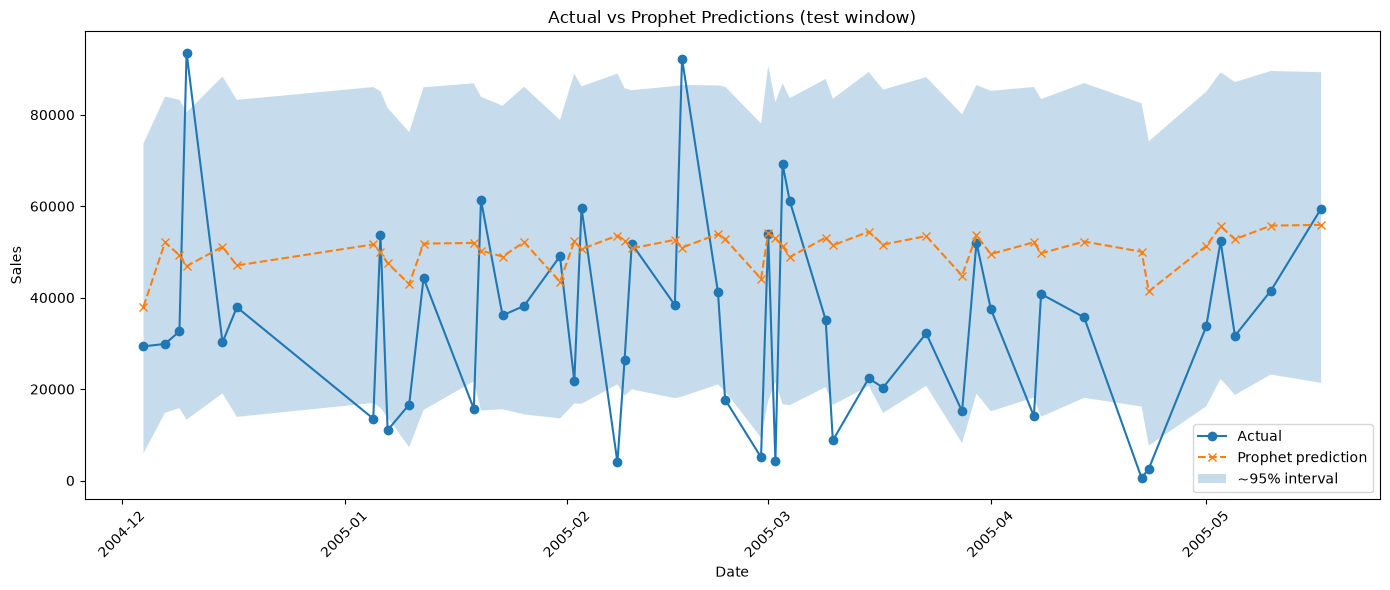

In [71]:
plt.figure(figsize=(14, 6))
plt.plot(results["ds"], results["y"], marker="o", label="Actual")
plt.plot(results["ds"], results["yhat"], marker="x", linestyle="--", label="Prophet prediction")
plt.fill_between(results["ds"], results["yhat_lower"], results["yhat_upper"],
                 alpha=0.25, label="~95% interval")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.title("Actual vs Prophet Predictions (test window)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 7. What is the model assuming?

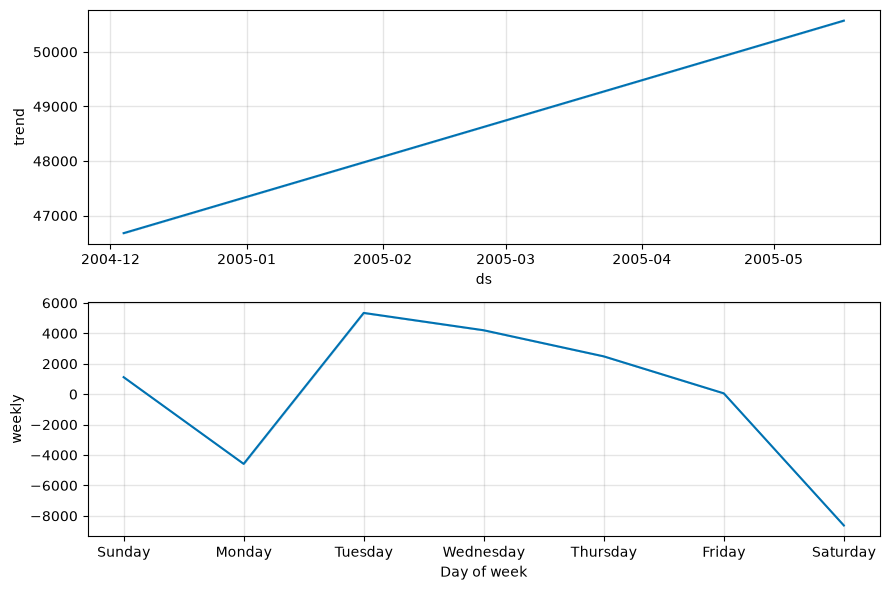

In [72]:
fig = model.plot_components(forecast_test)
plt.show()

**Trend** 

The component plot shows a smooth, nearly linear upward trend from roughly 46,700 (late 2004) to just over 50,500 (May 2005). This is consistent with genuine growth rather than the model simply chasing short-term noise: Prophet’s trend is deliberately heavily regularized and piecewise-linear, so a steady multi-month rise of this magnitude is unlikely to be an artifact of local fluctuations. (Whether the same slope held throughout 2003–2004 would need the full historical trend plot, but the segment shown here supports a real underlying increase.)

**Weekly**

the day-of-week pattern matches the weekday-gap analysis from notebook 01.

Weekends are sparse: Saturday is strongly negative (≈ –8 000), Sunday only mildly positive.
Mid-week is busier: a clear peak on Tuesday (≈ +5 000) that remains elevated through Wednesday and then declines through Thursday/Friday.
This is exactly the “sparse weekends, busier mid-week” signature observed earlier.

## 8. Experiment: enabling yearly seasonality

EDA suggested an Oct–Dec peak.

In [73]:
model_yearly = Prophet(
    weekly_seasonality=True,
    yearly_seasonality=True,
    daily_seasonality=False,
)
model_yearly.fit(train)

forecast_test_yearly = model_yearly.predict(test[["ds"]])
results_yearly = test.merge(
    forecast_test_yearly[["ds", "yhat", "yhat_lower", "yhat_upper"]],
    on="ds",
)
assert len(results_yearly) == len(test)

scores_yearly = evaluate(results_yearly["y"], results_yearly["yhat"], label="Prophet (yearly)")
print()
scores_default = evaluate(results["y"], results["yhat"], label="Prophet (default)")

Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
12:58:40 - cmdstanpy - INFO - Chain [1] start processing
12:58:40 - cmdstanpy - INFO - Chain [1] done processing


  Prophet (yearly) -> MAE: $   17,207 | RMSE: $   20,489 | MAPE:  202.0%

 Prophet (default) -> MAE: $   21,965 | RMSE: $   26,272 | MAPE:  360.1%


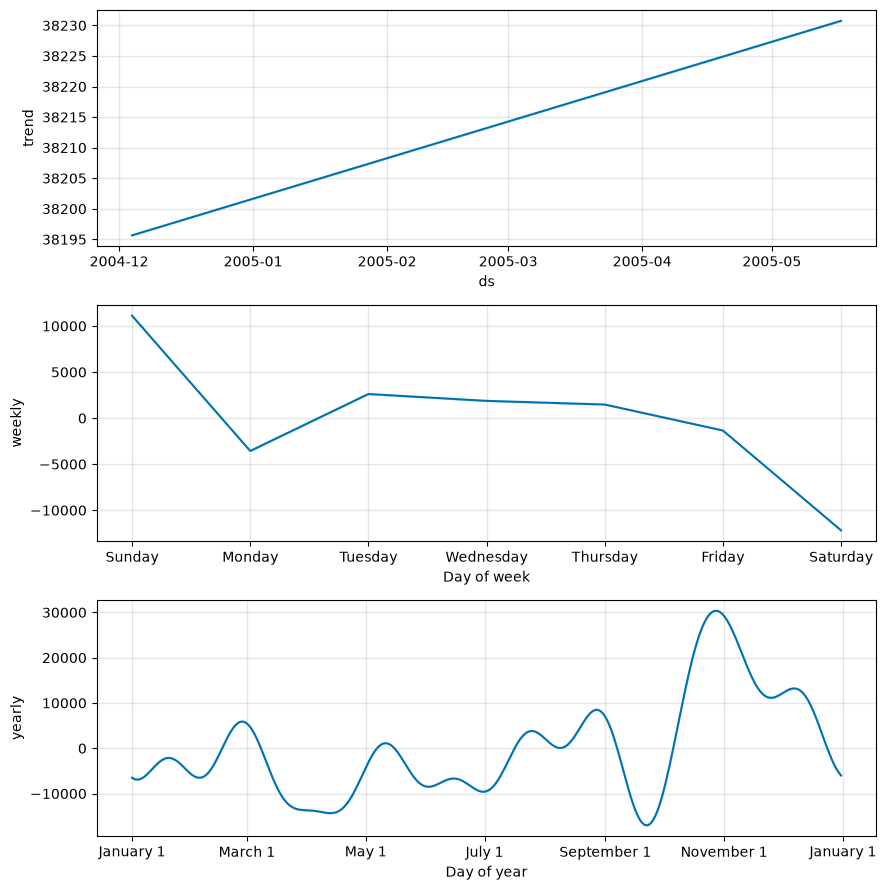

In [74]:
fig = model_yearly.plot_components(forecast_test_yearly)
plt.show()

The yearly seasonal component (now enabled) exhibits a pronounced late-year peak: a sharp rise into early November reaching ≈ +30 000, a secondary shoulder in December (≈ +12–13 000), then a rapid decline into January. Smaller positive excursions appear in March, May, July and September, with a deep trough around late September / early October. This shape is consistent with the Oct–Dec pattern identified in the EDA.

## 9. Cross-validation (rolling-origin, on the training data only)

A single 48-day test window is a small sample for comparing configurations.
Prophet's `cross_validation` simulates forecasting at multiple cut dates
inside the training data, giving error-by-horizon curves.

⚠️ **Fix vs the earlier attempt:** the previous run used `initial="365 days"`,
but Prophet warned that the yearly seasonality period (365.25 days) is larger
than the initial window. The initial window must exceed the longest
seasonality period, so we use ~500 days (the train span is ~700 days).

In [75]:
from prophet.diagnostics import cross_validation, performance_metrics

df_cv = cross_validation(
    model_yearly,          # or `model` to CV the default config
    initial="500 days",
    period="60 days",
    horizon="90 days",
    parallel="threads",
)
df_p = performance_metrics(df_cv)
df_p.head()

13:08:32 - cmdstanpy - INFO - Chain [1] start processing
13:08:32 - cmdstanpy - INFO - Chain [1] start processing
13:08:32 - cmdstanpy - INFO - Chain [1] done processing
13:08:32 - cmdstanpy - INFO - Chain [1] done processing


,horizon,mse,rmse,mae,mape,mdape,smape,coverage
0,10 days,9.978236e+08,31588.346688,24477.736966,1.678273,0.593769,0.759239,0.500000
1,11 days,1.013761e+09,31839.620442,25503.134943,1.696283,0.593769,0.789811,0.500000
2,12 days,8.250337e+08,28723.400229,20650.876109,1.000672,0.415444,0.598193,0.666667
3,13 days,1.883064e+08,13722.477051,11755.193057,0.926298,0.283885,0.472818,0.833333
4,14 days,2.791835e+08,16708.786141,14505.377190,0.950533,0.336423,0.506036,0.833333


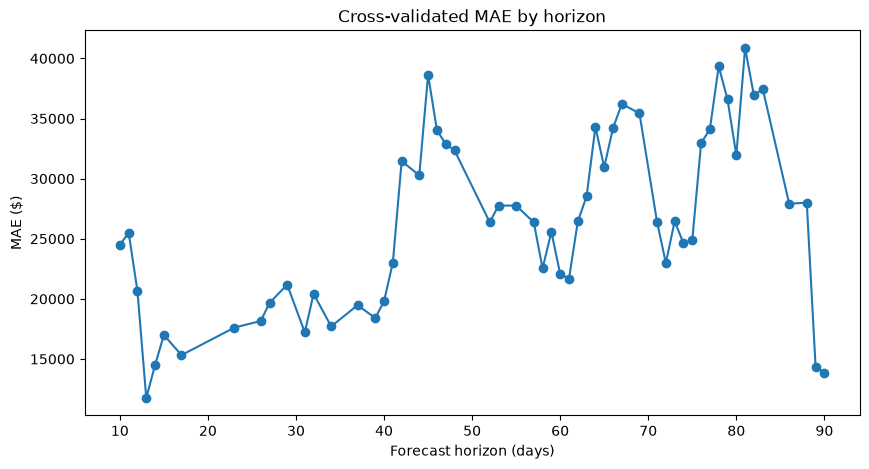

In [76]:
# MAE by forecast horizon — how does error grow as we predict further ahead?
horizon_mae = df_p.groupby("horizon")["mae"].mean().reset_index()
horizon_mae["horizon_days"] = horizon_mae["horizon"].dt.days
horizon_mae = horizon_mae.sort_values("horizon_days")

plt.figure(figsize=(10, 5))
plt.plot(horizon_mae["horizon_days"], horizon_mae["mae"], marker="o")
plt.xlabel("Forecast horizon (days)")
plt.ylabel("MAE ($)")
plt.title("Cross-validated MAE by horizon")
plt.show()

Cross-validated MAE starts in the $12–25 k range for the shortest horizons (≈10–20 days) and then rises, with clear volatility and spikes reaching $35–40 k around the 45-day and 75–80-day marks.
This pattern is expected: forecast uncertainty compounds with horizon length. The relatively steep overall climb (and the large swings) shows that the model is mainly reliable for short-term forecasts. Beyond roughly 30 days the error becomes both larger and less stable.

## 10. Summary

| Model                        | MAE      | RMSE     | MAPE   |
|:---|:---:|:---:|---:|
| Naive baseline               | \$25,532 | \$31,122 | 265.2% |
| Prophet (default)            | \$21,965 | \$26,272 | 360.1% |
| Prophet (yearly seasonality) | \$17,207 | \$20,489 | 202.0% |

**Decisions & observations:**
- Same test window, same metrics — comparisons must be apples-to-apples.
- Both Prophet configs beat the naive baseline on MAE and RMSE. Enabling yearly seasonality gives the clearest gain (MAE drops from ~$22 k → ~$17 k).
- MAPE remains extremely high for all models because the series contains many low/near-zero days; treat MAE/RMSE as the primary metrics.
- LSTM’s realistic goal is a further modest improvement on the best Prophet result (~$17 k MAE), not a dramatic leap.

In [77]:
# Persist scores for the final model comparison (notebook 04)
import json

Path("results").mkdir(exist_ok=True)
scores = {
    "naive_baseline":     {k: float(v) for k, v in scores_naive.items()},
    "prophet_default":    {k: float(v) for k, v in scores_default.items()},
    "prophet_yearly":     {k: float(v) for k, v in scores_yearly.items()},
}
with open("results/test_scores.json", "w") as f:
    json.dump(scores, f, indent=2)

scores

{'naive_baseline': {'MAE': 25532.18770833334,
  'RMSE': 31121.507226395872,
  'MAPE': 265.23098376784577},
 'prophet_default': {'MAE': 21965.41943133349,
  'RMSE': 26272.133284177526,
  'MAPE': 360.1252176454205},
 'prophet_yearly': {'MAE': 17207.10079041587,
  'RMSE': 20489.346786108214,
  'MAPE': 202.0305562352774}}